# 02 - Instrument response functions and exposure

`IRFExtractor` wraps the gammapy readers for the CTAO (prod3b / prod5) IRF files shipped with
the package and exposes the four response functions as torch-friendly log functions:

| method | returns |
|---|---|
| `log_aeff(E, lon, lat, pointing_dir)` | $\log A_\mathrm{eff}$ [cm²] |
| `log_edisp(E_reco, E_true, lon, lat)` | $\log$ energy-dispersion density [TeV⁻¹] |
| `log_psf(lon_reco, lat_reco, E_true, lon, lat)` | $\log$ PSF [deg⁻²] |
| `log_bkg_CCR(E, lon, lat)` | $\log$ residual cosmic-ray background rate [deg⁻² TeV⁻¹ s⁻¹] |

plus two helpers that summarise the PSF for the forward operator
(`psf_containment_radius`, `psf_sigma_vs_energy`).  `GammaLogExposure` turns $A_\mathrm{eff}$,
live time and bin volume into the exposure cube every flux prior is multiplied with.

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple MPS: run the few unsupported ops on the CPU
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"
# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64, so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_default_dtype(torch.float32 if device == "mps" else torch.float64)   # float64 where available: exactness over speed
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning, GammaLogExposure
from gammabayes.response_functions import IRFExtractor
npy = lambda t: t.detach().cpu().numpy()

geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100.,
                    lon_res=10, lon_min=-3., lon_max=3., lat_res=10, lat_min=-3., lat_max=3.)

torch 2.15.0 on mps (torch.float32), FAST=False


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[wall time: 3.1 s]


## Loading the IRFs

The prod5 tarball is unpacked under `gammabayes/package_data` on first use (a few seconds).
`irf_time_seconds` selects the IRF *optimisation* (cuts tuned for 0.5 h, 5 h or 50 h
observations); it is independent of your live time. 

In [2]:
pointing = torch.tensor([0., 0.])                 # Galactic Centre
irfs = IRFExtractor(zenith_angle=20, hemisphere="South", prod_vers=5,
                    pointing_dir=pointing, irf_time_seconds=180000)      # 50 h optimisation
print(irfs.irf_file_path.split("/")[-1])
print("units: aeff", irfs.aeff_units, " psf", irfs.psf_units, " edisp", irfs.edisp_units, " bkg", irfs.CCR_BKG_units)

Prod5-South-20deg-AverageAz-14MSTs37SSTs.180000s-v0.1.fits.gz
units: aeff cm2  psf 1 / deg2  edisp 1 / TeV  bkg 1 / (TeV s deg2)


[wall time: 85 ms]


## Effective area

`log_aeff` evaluates $A_\mathrm{eff}(E_\mathrm{true}, \theta)$ with $\theta$ the angular offset from the
pointing direction (great-circle distance).  Outside the tabulated energy range gammapy returns
`NaN`; below the lowest tabulated area it returns 0, which `log_aeff` floors at $e^{-100}$.

log A_eff cube: (30, 60, 60)  NaN planes: 0


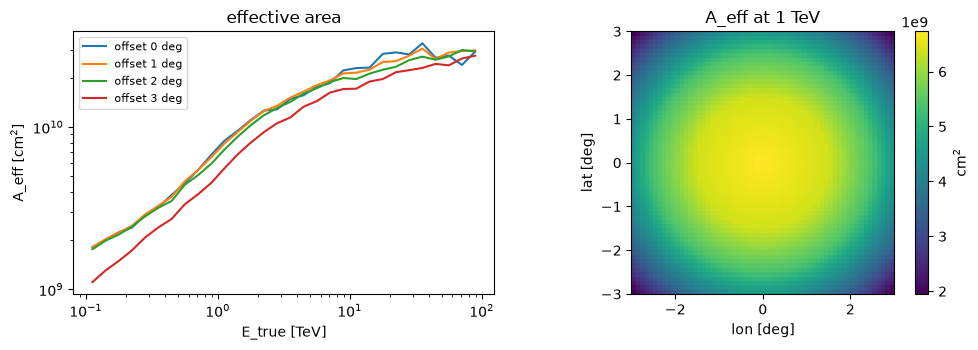

[wall time: 348 ms]


In [3]:
log_aeff = irfs.log_aeff(*geom.axes_mesh, pointing_dir=pointing)        # (E, lon, lat)
print("log A_eff cube:", tuple(log_aeff.shape), " NaN planes:", int(torch.isnan(log_aeff).all((1, 2)).sum()))

E = npy(geom.energy_axis)
ic, jc = len(geom.lon_axis) // 2, len(geom.lat_axis) // 2
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for off in (0, 1, 2, 3):
    j = int(torch.argmin((geom.lon_axis - off).abs()))
    ax[0].loglog(E, np.exp(npy(log_aeff[:, j, jc])), label=f"offset {off} deg")
ax[0].set(xlabel="E_true [TeV]", ylabel="A_eff [cm$^2$]", title="effective area")
ax[0].legend(fontsize=8)
k = int(torch.argmin((geom.energy_axis - 1.).abs()))
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), np.exp(npy(log_aeff[k])).T, shading="auto")
ax[1].set(xlabel="lon [deg]", ylabel="lat [deg]", title="A_eff at 1 TeV", aspect="equal")
plt.colorbar(pcm, ax=ax[1], label="cm$^2$")
plt.tight_layout()

## Point spread function

The forward operator uses a Gaussian PSF whose width may depend on true energy.
`psf_containment_radius` integrates the tabulated PSF to the requested containment fraction;
`psf_sigma_vs_energy` averages $R_{68}$ over the field of view (weighted by $A_\mathrm{eff}$,
uniformly, or by a counts cube) and converts to the equivalent Gaussian
$\sigma = R_{68} / \sqrt{-2\ln(1-0.68)} = R_{68}/1.51$.  `pixel_floor=True` adds the pixel variance
in quadrature so that sub-pixel PSFs do not collapse to a delta kernel.

sigma(E) from 0.100 deg at 0.11 TeV to 0.018 deg at 89.1 TeV


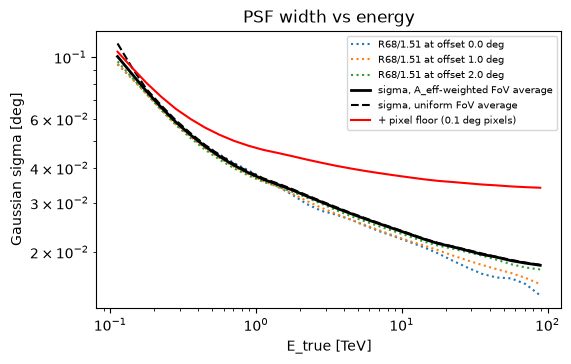

[wall time: 252 ms]


In [4]:
R68 = irfs.psf_containment_radius(E, offset=[0., 1., 2.], fraction=0.68)       # (E, 3) numpy
sigma_aeff = irfs.psf_sigma_vs_energy(geom, fraction=0.68, weighting="aeff", pointing_dir=pointing, pixel_floor=False)
sigma_unif = irfs.psf_sigma_vs_energy(geom, fraction=0.68, weighting="uniform", pointing_dir=pointing, pixel_floor=False)
sigma_floor = irfs.psf_sigma_vs_energy(geom, fraction=0.68, weighting="aeff", pointing_dir=pointing, pixel_floor=True)

fig, ax = plt.subplots(figsize=(6, 3.6))
for i, off in enumerate((0., 1., 2.)):
    ax.loglog(E, R68[:, i] / 1.5096, ":", label=f"R68/1.51 at offset {off} deg")
ax.loglog(E, npy(sigma_aeff), "k-", lw=2, label="sigma, A_eff-weighted FoV average")
ax.loglog(E, npy(sigma_unif), "k--", label="sigma, uniform FoV average")
ax.loglog(E, npy(sigma_floor), "r-", label="+ pixel floor (0.1 deg pixels)")
ax.set(xlabel="E_true [TeV]", ylabel="Gaussian sigma [deg]", title="PSF width vs energy")
ax.legend(fontsize=7)
print("sigma(E) from %.3f deg at %.2g TeV to %.3f deg at %.3g TeV" % (sigma_aeff[0], E[0], sigma_aeff[-1], E[-1]))

## Energy dispersion

The energy kernel of the forward operator is a Gaussian in $\log_{10}E$ with width
$\sigma_{\log_{10}E}$ **in dex**.  It can be read off the tabulated migration matrix
$P(\mu = E_\mathrm{reco}/E_\mathrm{true} \,|\, E_\mathrm{true})$ as the weighted standard deviation of
$\log_{10}\mu$.  For CTAO South prod5 it is ≈ 0.09 dex above 0.3 TeV.  The gammapy object is
called directly with astropy quantities, which also works when the default torch device is a GPU.

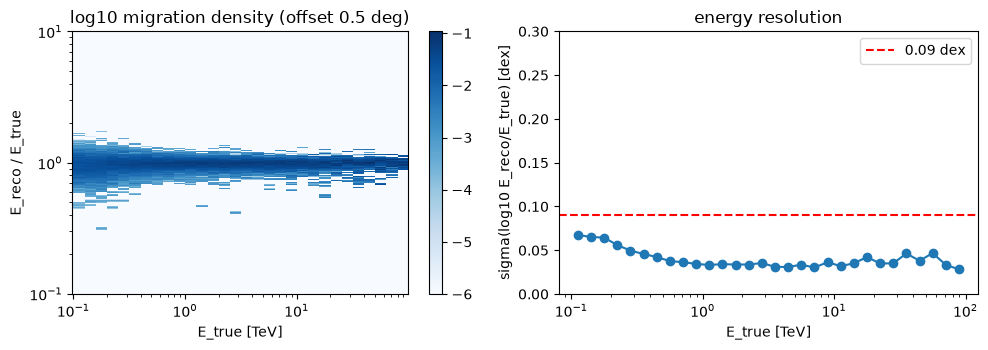

[wall time: 245 ms]


In [5]:
mu = np.logspace(-1, 1, 801)                               # E_reco / E_true
Et = E[:, None] * u.TeV
pdf = irfs.edisp_default.evaluate(energy_true=Et, migra=mu[None, :], offset=0.5 * u.deg)   # (E, mu) density in 1/mu
pdf = np.asarray(getattr(pdf, "value", pdf))
w = pdf * mu[None, :]                                      # density per d(log mu)
w = w / np.maximum(w.sum(1, keepdims=True), 1e-300)
mean = (w * np.log10(mu)[None]).sum(1)
sig_dex = np.sqrt((w * (np.log10(mu)[None] - mean[:, None]) ** 2).sum(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
pcm = ax[0].pcolormesh(E, mu, np.log10(np.maximum(pdf, 1e-6)).T, shading="auto", cmap="Blues")
ax[0].set(xscale="log", yscale="log", xlabel="E_true [TeV]", ylabel="E_reco / E_true", title="log10 migration density (offset 0.5 deg)")
plt.colorbar(pcm, ax=ax[0])
ax[1].semilogx(E, sig_dex, "o-")
ax[1].axhline(0.09, color="r", ls="--", label="0.09 dex")
ax[1].set(xlabel="E_true [TeV]", ylabel="sigma(log10 E_reco/E_true) [dex]", ylim=(0, 0.3), title="energy resolution")
ax[1].legend()
plt.tight_layout()

## Residual cosmic-ray background

`log_bkg_CCR` is a **reconstructed-space rate density** (per deg², TeV and second).  It is not
multiplied by $A_\mathrm{eff}$ (the IRF producers already folded the acceptance in), so the expected
CCR counts are `exp(log_bkg_CCR + log(t_live * bin volume))`.  The forward operator must not be
applied to it: it is added *after* the gamma-ray model has been smeared.

CCR counts in 500 h: 5.65e+07 total, 5.53e+05 in the 1-TeV plane


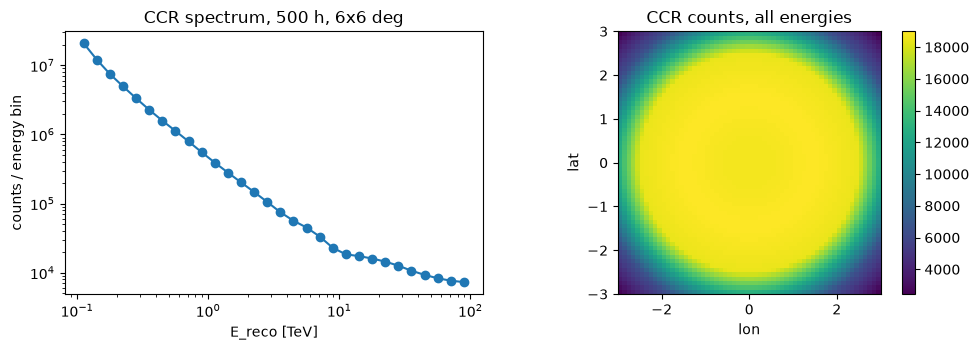

[wall time: 245 ms]


In [6]:
g = geom.shaped_grid
log_ccr_rate = irfs.log_bkg_CCR(g[..., 0].flatten(), g[..., 1].flatten(), g[..., 2].flatten(), pointing_dir=pointing).reshape(geom.shape)
t_live = 500 * 3600.                                                        # 500 h in seconds
ccr_counts = torch.exp(log_ccr_rate + math.log(t_live) + torch.log(geom.bin_width_mat))
print("CCR counts in 500 h: %.3g total, %.3g in the 1-TeV plane" % (ccr_counts.sum(), ccr_counts[k].sum()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].loglog(E, npy(ccr_counts.sum((1, 2))), "o-")
ax[0].set(xlabel="E_reco [TeV]", ylabel="counts / energy bin", title="CCR spectrum, 500 h, 6x6 deg")
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), npy(ccr_counts.sum(0)).T, shading="auto")
ax[1].set(xlabel="lon", ylabel="lat", aspect="equal", title="CCR counts, all energies")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

## Exposure

$$X_{ijk} = A_\mathrm{eff}(E_i, \theta_{jk})\; t_\mathrm{live}\; \Delta E_i\, \Delta l_j\, \Delta b_k
\qquad [\mathrm{cm^2\,s\,TeV\,deg^2}]$$

`GammaLogExposure` builds $\log X$ for one or more pointings (`pointing_dirs` is a list of
`[lon, lat]`, `live_times` a list of quantities or seconds) and `logaddexp`s them.  Pass
`use_log_aeff=False` for the "no-acceptance" exposure $t\,\Delta V$ used with the CCR
template.  Bins where $A_\mathrm{eff}$ is undefined get $\log X = -\infty$ (zero counts), which every
downstream operator tolerates.

exposure unit: cm2 s  live times [s]: [1.8e+06]  pointings: [[0. 0.]]
log X: (30, 60, 60)  finite fraction: 1.000
no-aeff exposure at 1 TeV, centre = t * dV = 3702  (check 3702)


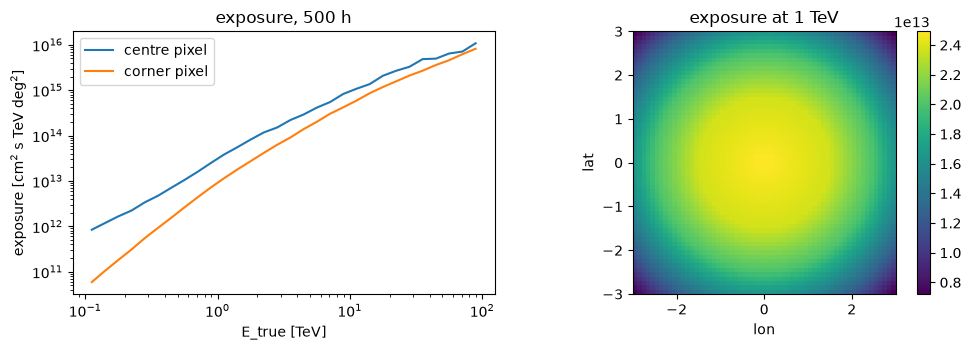

[wall time: 395 ms]


In [7]:
logexp = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)
logexp_noaeff = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr, use_log_aeff=False)
print("exposure unit:", logexp.unit, " live times [s]:", npy(logexp.live_times), " pointings:", npy(logexp.pointing_dirs))
X = logexp.log_exposure_map
print("log X:", tuple(X.shape), " finite fraction: %.3f" % torch.isfinite(X).float().mean())
print("no-aeff exposure at 1 TeV, centre = t * dV = %.4g  (check %.4g)" % (torch.exp(logexp_noaeff.log_exposure_map[k, ic, jc]), t_live * geom.bin_width_mat[k, ic, jc]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].loglog(E, np.exp(npy(X[:, ic, jc])), label="centre pixel")
ax[0].loglog(E, np.exp(npy(X[:, 0, 0])), label="corner pixel")
ax[0].set(xlabel="E_true [TeV]", ylabel="exposure [cm$^2$ s TeV deg$^2$]", title="exposure, 500 h")
ax[0].legend()
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), np.exp(npy(X[k])).T, shading="auto")
ax[1].set(xlabel="lon", ylabel="lat", aspect="equal", title="exposure at 1 TeV")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

### Evaluating the exposure on another grid

The exposure object is callable: `logexp(E, lon, lat)` interpolates $\exp X$ (not $\log X$, so
that $-\infty$ bins behave) and returns the log.  `SourceFluxDiscreteLogPrior` uses this to add
the exposure to a flux cube; it caches the result for the geometry's own grid.

In [8]:
e_q = torch.tensor([0.5, 1.0, 2.0])
l_q = torch.zeros(3)
b_q = torch.zeros(3)
print("log X at the centre for E = 0.5, 1, 2 TeV:", npy(logexp(e_q, l_q, b_q)))

log X at the centre for E = 0.5, 1, 2 TeV: [29.790009 31.073004 32.224617]


[wall time: 6 ms]


### Several pointings

Add observations with `+` (geometries must be equal) or by passing lists.  Live times may be
given in any time unit; they are stored in seconds.

summed exposure equals the two-pointing one: True


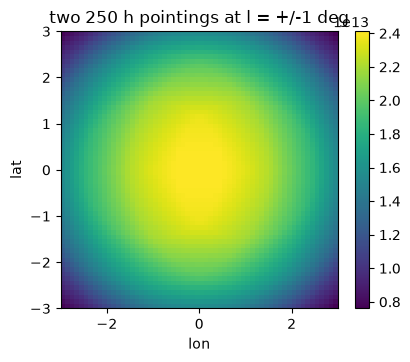

[wall time: 131 ms]


In [9]:
two = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[[-1., 0.], [1., 0.]], live_times=[250 * u.hr, 250 * u.hr])
fig, ax = plt.subplots(figsize=(4.5, 3.6))
pcm = ax.pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), np.exp(npy(two.log_exposure_map[k])).T, shading="auto")
ax.set(xlabel="lon", ylabel="lat", aspect="equal", title="two 250 h pointings at l = +/-1 deg")
plt.colorbar(pcm, ax=ax)
print("summed exposure equals the two-pointing one:",
      torch.allclose((GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[[-1., 0.]], live_times=250 * u.hr)
                      + GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[[1., 0.]], live_times=250 * u.hr)).log_exposure_map,
                     two.log_exposure_map, equal_nan=True))

## Exposure on the padded true grid

For the forward operator the exposure is needed on the **padded true geometry** (notebook 05).
Energies outside the IRF table give $-\infty$ exposure there, which is the physically correct
"no acceptance" statement.

In [10]:
tg = geom.padded((3, 4, 4))
tlogexp = GammaLogExposure(binning_geometry=tg, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)
print("true geometry:", tg.shape, " -inf energy planes:", int(torch.isneginf(tlogexp.log_exposure_map).all((1, 2)).sum()))

true geometry: (36, 68, 68)  -inf energy planes: 0


[wall time: 23 ms]
